In [38]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
df = pd.read_csv("lab_ticket_resolution.csv")

In [24]:
########## Task 1 #############

print("shape: \n", df.shape)
print("Data types: \n", df.dtypes)
print("stats: \n", df.describe(include="all"))
print("Missing Values: \n", df.isna().sum())
print ("first five rows: \n",df.head())

shape: 
 (240, 6)
Data types: 
 ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
stats: 
        ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000              

In [25]:
############# Task 2 ###############

y = df["resolution_hours"]
X = df.drop(columns= ["resolution_hours", "ticket_id", "lines_changed", "reopened"])

#
 #   Justification: I dropped 'resoultion_hours' because it is the target varaible so it can't be part of the feature matrix. 
  #                 I dropped 'ticket_id' because it is not a meaningful numerical value.
   #                I dropped 'lines_changed' because this feature is not available at the time of predicition in the real world.
    #               I dropped 'reopened' because this feature is not available at the time of predicition.
#


In [26]:
############ Task 3 ##############
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)

In [27]:
################# Task 4 AND 5 ######################


def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

dummy_model = DummyRegressor(strategy="mean")

dummy_model.fit(X_train, y_train)

dummy_results = evaluate_model(
    dummy_model, X_test, y_test
)

print("Dummy Regressor Results:")
print(dummy_results)

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_results = evaluate_model(
    linear_model, X_test, y_test
)

print("Linear Regression Results:")
print(linear_results)
########################### RESULTS ####################
#Dummy Regressor Results:
# {'MAE': 9.113951822916667, 'RMSE': np.float64(10.597684800766308), 'R2': -0.021016765260001957}
# Linear Regression Results:
# {'MAE': 2.90601298595026, 'RMSE': np.float64(3.572274354879709), 'R2': 0.8839886480141969}

Dummy Regressor Results:
{'MAE': 9.113951822916667, 'RMSE': np.float64(10.597684800766308), 'R2': -0.021016765260001957}
Linear Regression Results:
{'MAE': 2.90601298595026, 'RMSE': np.float64(3.572274354879709), 'R2': 0.8839886480141969}


In [39]:
################### TASK 6: Polynomial Regression ###################
cv = KFold(
    n_splits = 5,
    shuffle = True,
    random_state = 42
)

poly_models = {}
poly_cv_results = {}

for degree in [1, 2, 3]:

    poly_model = make_pipeline(
        PolynomialFeatures(
            degree = degree,
            include_bias = False
        ),
        StandardScaler(),
        LinearRegression()
    )

    scores = cross_validate(
        poly_model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        return_train_score=True
    )

    train_mae = -scores["train_score"].mean()
    validation_mae = -scores["test_score"].mean()

    poly_models[degree] = poly_model
    poly_cv_results[degree] = validation_mae

    print(f"Degree {degree}")
    print(f"  Training MAE:   {train_mae:.4f} hours")
    print(f"  Validation MAE: {validation_mae:.4f} hours")
    print(f"  Error gap:      {validation_mae - train_mae:.4f} hours")
    print()

best_degree = min(poly_cv_results, key=poly_cv_results.get)
best_poly_model = poly_models[best_degree]

print("Best polynomial degree:", best_degree)
print(f"Best polynomial CV MAE: {poly_cv_results[best_degree]:.4f}")

# RESULT
# Degree 1
#  Training MAE:   3.1231 hours
#  Validation MAE: 3.1682 hours
#  Error gap:      0.0451 hours

# Degree 2
#  Training MAE:   3.0576 hours
#  Validation MAE: 3.1313 hours
#  Error gap:      0.0737 hours

# Degree 3
#  Training MAE:   2.9897 hours
#  Validation MAE: 3.1620 hours
#  Error gap:      0.1723 hours

# Best polynomial degree: 2
# Best polynomial CV MAE: 3.1313

Degree 1
  Training MAE:   3.1231 hours
  Validation MAE: 3.1682 hours
  Error gap:      0.0451 hours

Degree 2
  Training MAE:   3.0576 hours
  Validation MAE: 3.1313 hours
  Error gap:      0.0737 hours

Degree 3
  Training MAE:   2.9897 hours
  Validation MAE: 3.1620 hours
  Error gap:      0.1723 hours

Best polynomial degree: 2
Best polynomial CV MAE: 3.1313


In [29]:

#################### TASK 7: Ridge Regression And Lasso Regression ############################

alphas = [0.01, 0.1, 1, 10, 100]

ridge_pipeline = make_pipeline(
    StandardScaler(),
    Ridge()
)

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"ridge__alpha": alphas},
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

best_ridge_model = ridge_search.best_estimator_

print("Best Ridge alpha:", ridge_search.best_params_["ridge__alpha"])
print(f"Ridge CV MAE: {-ridge_search.best_score_:.4f}")

ridge_results = evaluate_model(
    best_ridge_model,
    X_test,
    y_test
)

print("Ridge Test Results:", ridge_results)

# RESULTS: 
#    Best Ridge alpha: 0.01
#    Ridge CV MAE: 3.1682
#    Ridge Test Results: {'MAE': 2.906005109989087, 'RMSE': np.float64(3.572253043929424), 'R2': 0.8839900321770773}


# Lasso Regression

lasso_pipeline = make_pipeline(
    StandardScaler(),
    Lasso(max_iter=10000)
)

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"lasso__alpha": alphas},
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)

best_lasso_model = lasso_search.best_estimator_

print("Best Lasso alpha:", lasso_search.best_params_["lasso__alpha"])
print(f"Lasso CV MAE: {-lasso_search.best_score_:.4f}")

lasso_results = evaluate_model(
    best_lasso_model,
    X_test,
    y_test
)

print("Lasso Test Results:", lasso_results)

# RESULTS: 
#    Best Lasso alpha: 0.01
#    Lasso CV MAE: 3.1688
#    Lasso Test Results: {'MAE': 2.9071322031660514, 'RMSE': np.float64(3.5724371203914673), 'R2': 0.8839780759945925}

Best Ridge alpha: 0.01
Ridge CV MAE: 3.1682
Ridge Test Results: {'MAE': 2.906005109989087, 'RMSE': np.float64(3.572253043929424), 'R2': 0.8839900321770773}
Best Lasso alpha: 0.01
Lasso CV MAE: 3.1688
Lasso Test Results: {'MAE': 2.9071322031660514, 'RMSE': np.float64(3.5724371203914673), 'R2': 0.8839780759945925}


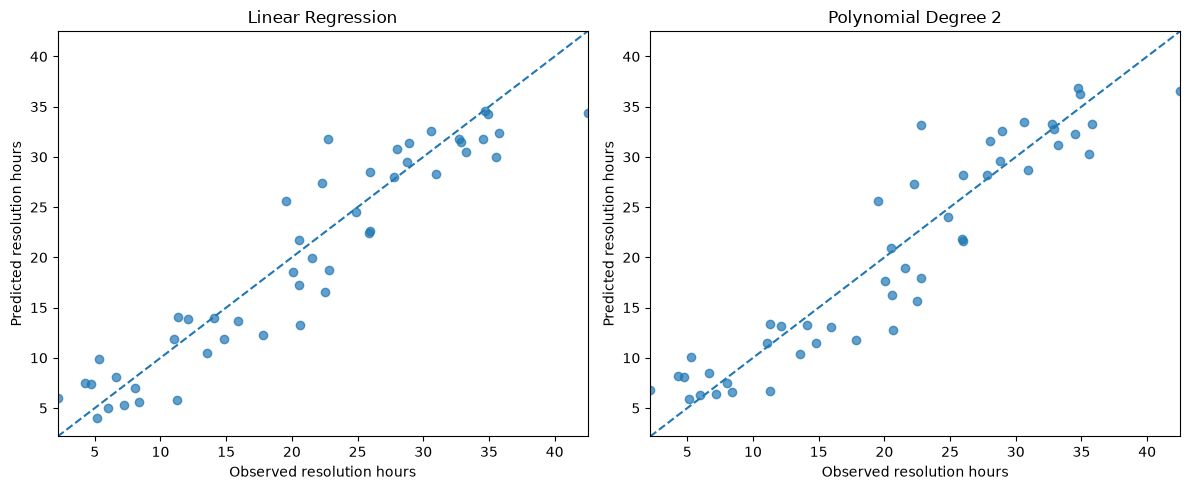

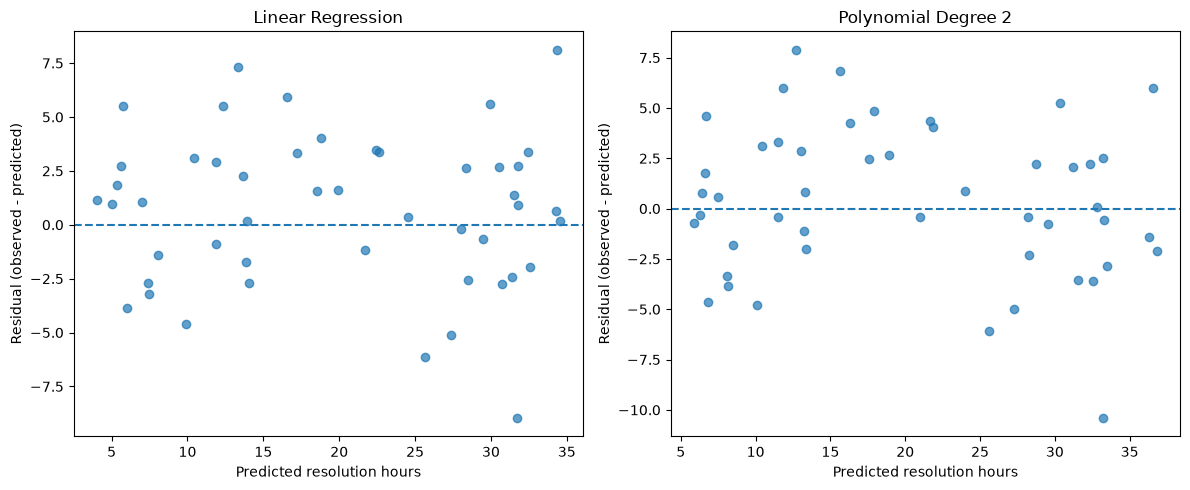

In [36]:
################### Task 8: plot #############################

best_poly_model.fit(X_train, y_train) # The polynomial model hasn't been properly fit on the full training data so far.

linear_predictions = linear_model.predict(X_test)
poly_predictions = best_poly_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("Linear Regression", linear_predictions),
    (f"Polynomial Degree {best_degree}", poly_predictions)
]

# Use common axis limits so both plots are comparable
lower = min(y_test.min(), linear_predictions.min(), poly_predictions.min())
upper = max(y_test.max(), linear_predictions.max(), poly_predictions.max())

for ax, (name, predictions) in zip(axes, models):
    ax.scatter(y_test, predictions, alpha=0.7)
    ax.plot([lower, upper], [lower, upper], linestyle="--")
    ax.set_xlabel("Observed resolution hours")
    ax.set_ylabel("Predicted resolution hours")
    ax.set_title(name)
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)

plt.tight_layout()
plt.show()

########## residual plot ###############

linear_residuals = y_test - linear_predictions
poly_residuals = y_test - poly_predictions

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

residual_models = [
    ("Linear Regression", linear_predictions, linear_residuals),
    (f"Polynomial Degree {best_degree}", poly_predictions, poly_residuals)
]

for ax, (name, predictions, residuals) in zip(axes, residual_models):
    ax.scatter(predictions, residuals, alpha=0.7)
    ax.axhline(y=0, linestyle="--")
    ax.set_xlabel("Predicted resolution hours")
    ax.set_ylabel("Residual (observed - predicted)")
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [1]:
########## Task 9: recommendation ##########

# I would choose Linear Regression because it achieved a test MAE of 2.91 hours, RMSE of 3.57 hours, and R2 of 0.884. 
# It performed much better than the Dummy Regressor, showing that the available features are useful for predicting ticket resolution time.

In [ ]:
########## Task 10: why mean baseline? #########

# The mean baseline provides a simple reference point by predicting the average resolution time for every ticket. 
# It helps determine whether more advanced models actually learn useful patterns from the features.

In [ ]:
########## Task 11 : Lowest MAE and RMSE #######

# Ridge Regression has the lowest MAE (2.906005 hours) and the lowest RMSE (3.572253 hours) among Linear Regression, Ridge, and Lasso. 
#Therefore, the same model has both the lowest MAE and lowest RMSE. 
#They might differ because MAE measures the average absolute prediction error, while RMSE gives more weight to large errors by squaring them before averaging. 
# A model with a few very large errors may have a relatively high RMSE even if its MAE is low.

In [ ]:
########### Task 12: overfitting ##############

# Polynomial features didn't meaningfully improve validation performance. Degree-2 Polynomial Regression achieved the 
# lowest validation MAE of 3.1313 hours, compared with 3.1682 hours for degree 1 and 3.1620 hours for degree 3. 
# Possible overfitting is indicated by degree 3 having a lower training MAE (2.9897 hours) but a higher validation MAE (3.1620 hours) than degree 2. 
# Its larger error gap of 0.1723 hours suggests that the more complex model fits the training data better without improving generalization.

In [ ]:
########### Task 13: Regularization ############ 

# Regularization slightly(very very slightly) affected model performance by penalizing large coefficients.
# Ridge (alpha = 0.01) achieved a test MAE of 2.906005 hours, while Linear Regression achieved 2.906013 hours and Lasso achieved 2.9071 hours. 
# Their performance was almost identical, with Ridge performing marginally better. The data wanted almost no regularization.

In [ ]:
########## Task 14: Scaling in Ridge and Lasso #########

# Scaling is included in the Ridge/Lasso pipeline to put all features on a comparable scale. 
# Ridge and Lasso penalize coefficient magnitudes, so features with larger numerical ranges could otherwise be treated unfairly.

In [ ]:
########### Task 15: Leakage ###########

# The main leakage risk is lines_changed: it is only known after the fix is done, so it
# would not be available when a ticket is created. reopened has the same problem.
# I handled this problem by excluded both from X and kept only complexity_score and team_experience_years, which
# are known at intake. 

In [ ]:
############## Task 16: Random Split ###############

# No, we can't randomly split. Tickets from the same customer or team could appear in both training and test sets, leading to overly optimistic results. 
# For data collected over several years, I would use a time-based split to train on older tickets and test on newer ones. 
# For repeated customers or teams, I would use a group-based split to ensure the same customer or team does not appear in both sets.

In [ ]:
############# Task 17: Additional Tests ################

# Before deploying the model, I would test it on new, unseen tickets to check whether it generalizes well.
# I would compare MAE, RMSE, and R2, examine residual plots for patterns and outliers, and check for data leakage.